# E-Commerce Customer Behavior and Recommendation Analytics

**Big Data Minor Project — Project #6**

This notebook walks through the full pipeline step by step: Bronze → Silver → Gold layers with PySpark and Spark SQL, exploratory analysis, K-Means customer segmentation and ALS product recommendations with Spark MLlib.

**Problem statement:** Using ~1M real transactions from a UK online retailer, identify sales patterns, segment customers by value (RFM), and recommend products each customer is likely to buy next.

**Dataset:** Chen, D. (2012). *Online Retail II*. UCI Machine Learning Repository. https://doi.org/10.24432/C5CG6D (CC BY 4.0) — 1,067,371 rows, Dec 2009 – Dec 2011.

> Run `./run_pipeline.sh` (macOS/Linux) or `run_pipeline.ps1` (Windows) once before this notebook so the Bronze/Silver/Gold layers exist in `data/`.

## 1. Setup — Spark session

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, os.path.abspath("../src"))

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from config import BRONZE_DIR, SILVER_DIR, GOLD_DIR, get_spark

%matplotlib inline
plt.rcParams["figure.figsize"] = (11, 4)
spark = get_spark("notebook_walkthrough")
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/15 20:16:13 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark version: 4.2.0


## 2. Bronze layer — raw data with ingestion metadata
`01_ingest_bronze.py` downloads the zip, converts both Excel sheets (2009-10 and 2010-11) to CSV, and stores them as Parquet **without changing values** (all columns kept as strings), adding `source_system`, `source_file` and `ingested_at` for lineage.

In [2]:
bronze = spark.read.parquet(BRONZE_DIR)
print(f"Bronze rows: {bronze.count():,}")
bronze.printSchema()
bronze.show(5, truncate=False)

Bronze rows: 1,067,371
root
 |-- invoice: string (nullable = true)
 |-- stockcode: string (nullable = true)
 |-- description: string (nullable = true)
 |-- quantity: string (nullable = true)
 |-- invoicedate: string (nullable = true)
 |-- price: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- country: string (nullable = true)
 |-- source_sheet: string (nullable = true)
 |-- source_system: string (nullable = true)
 |-- source_file: string (nullable = true)
 |-- ingested_at: timestamp (nullable = true)



+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+--------------+------------------------------------------+--------------------+--------------------------+
|invoice|stockcode|description                        |quantity|invoicedate        |price|customer_id|country       |source_sheet  |source_system                             |source_file         |ingested_at               |
+-------+---------+-----------------------------------+--------+-------------------+-----+-----------+--------------+--------------+------------------------------------------+--------------------+--------------------------+
|489434 |85048    |15CM CHRISTMAS GLASS BALL 20 LIGHTS|12      |2009-12-01 07:45:00|6.95 |13085      |United Kingdom|Year 2009-2010|UCI Online Retail II (doi:10.24432/C5CG6D)|online_retail_ii.csv|2026-10-15 19:20:50.127979|
|489434 |79323P   |PINK CHERRY LIGHTS                 |12      |2009-12-01 07:45:00|6.75 |13085      |Un

### Data quality check on the raw data — missing values per column

In [3]:
nulls = bronze.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in
                       ["invoice", "stockcode", "description", "quantity", "invoicedate", "price", "customer_id", "country"]])
nulls.toPandas().T.rename(columns={0: "null_count"})

,null_count
invoice,0
stockcode,0
description,4382
quantity,0
invoicedate,0
price,0
customer_id,243007
country,0


In [4]:
# How many rows are cancellations, negative quantities or zero prices?
bronze.selectExpr(
    "SUM(CASE WHEN invoice LIKE 'C%' THEN 1 ELSE 0 END) AS cancellations",
    "SUM(CASE WHEN CAST(quantity AS INT) <= 0 THEN 1 ELSE 0 END) AS non_positive_qty",
    "SUM(CASE WHEN CAST(price AS DOUBLE) <= 0 THEN 1 ELSE 0 END) AS non_positive_price",
    "COUNT(*) - COUNT(DISTINCT *) AS exact_duplicates"
).show()

+-------------+----------------+------------------+----------------+
|cancellations|non_positive_qty|non_positive_price|exact_duplicates|
+-------------+----------------+------------------+----------------+
|        19494|           22950|              6207|          255003|
+-------------+----------------+------------------+----------------+



## 3. Silver layer — cleaned and typed data
`02_silver.py` casts types, trims/uppercases text, drops exact duplicates, removes rows without a customer, removes non-product codes (POST, BANK CHARGES, manual adjustments…) and invalid quantities/prices, and stores cancellations in a separate table. Sales are partitioned by `year_month`.

In [5]:
with open(os.path.join(SILVER_DIR, "quality_report.json")) as f:
    report = json.load(f)
pd.Series(report, name="rows").to_frame()

,rows
bronze_rows,1067371
after_dedup,1033036
silver_sales_rows,776579
silver_cancellation_rows,17602
removed_rows,273190


In [6]:
sales = spark.read.parquet(os.path.join(SILVER_DIR, "sales"))
sales.createOrReplaceTempView("sales")
sales.printSchema()
sales.select("quantity", "price", "line_total").describe().show()

root
 |-- invoice: string (nullable = true)
 |-- stock_code: string (nullable = true)
 |-- description: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- invoice_ts: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- customer_id: integer (nullable = true)
 |-- country: string (nullable = true)
 |-- line_total: double (nullable = true)
 |-- invoice_date: date (nullable = true)
 |-- year_month: string (nullable = true)



+-------+------------------+-----------------+------------------+
|summary|          quantity|            price|        line_total|
+-------+------------------+-----------------+------------------+
|  count|            776579|           776579|            776579|
|   mean|13.519214400595432|2.934561300268128|21.979196862134582|
| stddev| 146.0965082476063|4.293604926511122|225.93269292845633|
|    min|                 1|             0.03|              0.06|
|    max|             80995|            649.5|          168469.6|
+-------+------------------+-----------------+------------------+



## 4. Exploratory analysis with Spark SQL

### 4.1 Monthly revenue with month-over-month growth (window function `LAG`)

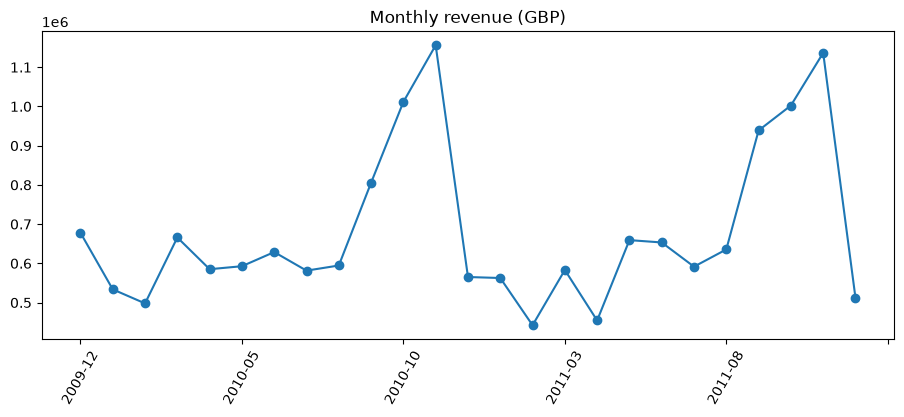

,year_month,revenue,customers,mom_growth_pct
19,2011-07,591604.0,946,-9.4
20,2011-08,635514.0,933,7.4
21,2011-09,938753.0,1259,47.7
22,2011-10,1002327.0,1361,6.8
23,2011-11,1136534.0,1660,13.4
24,2011-12,512228.0,614,-54.9


In [7]:
monthly = spark.sql("""
    WITH m AS (SELECT year_month, SUM(line_total) AS revenue, COUNT(DISTINCT customer_id) AS customers
               FROM sales GROUP BY year_month)
    SELECT year_month, ROUND(revenue, 0) AS revenue, customers,
           ROUND(100 * (revenue / LAG(revenue) OVER (ORDER BY year_month) - 1), 1) AS mom_growth_pct
    FROM m ORDER BY year_month
""").toPandas()

ax = monthly.plot(x="year_month", y="revenue", marker="o", legend=False, title="Monthly revenue (GBP)")
ax.set_xlabel(""); plt.xticks(rotation=60); plt.show()
monthly.tail(6)

Revenue is clearly **seasonal**: it peaks every November before Christmas. (December 2011 is low only because the data ends on 9 Dec 2011.)

### 4.2 Top products and countries

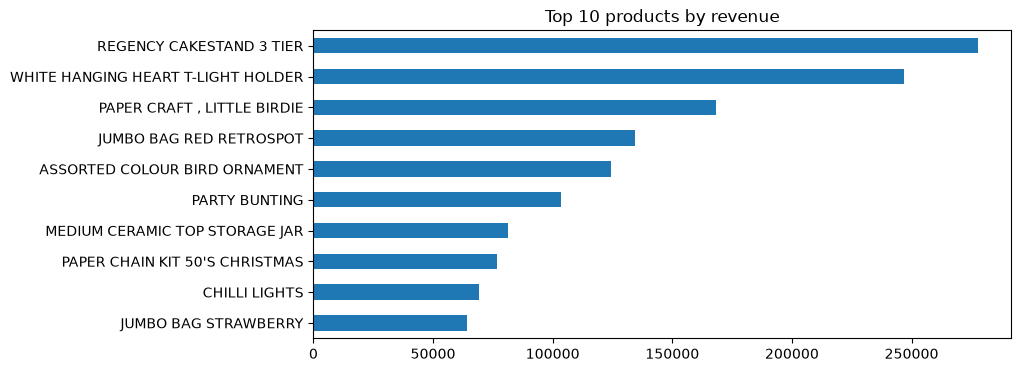

In [8]:
top_products = spark.sql("""
    SELECT description, ROUND(SUM(line_total), 0) AS revenue, SUM(quantity) AS units
    FROM sales GROUP BY description ORDER BY revenue DESC LIMIT 10
""").toPandas()
top_products.sort_values("revenue").plot.barh(x="description", y="revenue", legend=False,
                                              title="Top 10 products by revenue", figsize=(9, 4))
plt.ylabel(""); plt.show()

In [9]:
spark.sql("""
    SELECT country, ROUND(SUM(line_total), 0) AS revenue, COUNT(DISTINCT customer_id) AS customers,
           ROUND(100 * SUM(line_total) / SUM(SUM(line_total)) OVER (), 2) AS revenue_share_pct
    FROM sales GROUP BY country ORDER BY revenue DESC LIMIT 10
""").show(truncate=False)

+--------------+-----------+---------+-----------------+
|country       |revenue    |customers|revenue_share_pct|
+--------------+-----------+---------+-----------------+
|United Kingdom|1.4288773E7|5334     |83.71            |
|Eire          |586626.0   |3        |3.44             |
|Netherlands   |549773.0   |22       |3.22             |
|Germany       |383289.0   |107      |2.25             |
|France        |309403.0   |93       |1.81             |
|Australia     |167800.0   |15       |0.98             |
|Spain         |97767.0    |38       |0.57             |
|Switzerland   |93401.0    |22       |0.55             |
|Sweden        |86045.0    |19       |0.5              |
|Denmark       |67423.0    |12       |0.4              |
+--------------+-----------+---------+-----------------+



The UK accounts for the large majority of revenue; EIRE, Netherlands and Germany are the biggest export markets.

### 4.3 When do customers order? (weekday × hour)

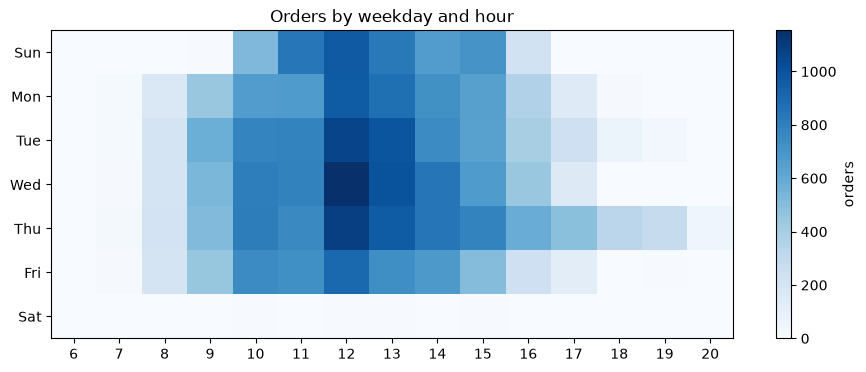

In [10]:
heat = spark.sql("""
    SELECT dayofweek(invoice_ts) AS dow, hour(invoice_ts) AS hour, COUNT(DISTINCT invoice) AS orders
    FROM sales GROUP BY 1, 2
""").toPandas().pivot(index="dow", columns="hour", values="orders").fillna(0)
heat.index = [["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"][i - 1] for i in heat.index]
plt.imshow(heat, aspect="auto", cmap="Blues")
plt.yticks(range(len(heat.index)), heat.index); plt.xticks(range(len(heat.columns)), heat.columns)
plt.colorbar(label="orders"); plt.title("Orders by weekday and hour"); plt.show()

Orders are placed during UK business hours (peak around 12:00) and almost never on Saturdays — consistent with many customers being wholesalers.

## 5. Gold layer — customer RFM features
For every customer we compute **Recency** (days since last purchase), **Frequency** (number of orders) and **Monetary** (total spend), then score each 1–5 with `NTILE(5)` window functions (built in `03_gold.py`).

In [11]:
rfm = spark.read.parquet(os.path.join(GOLD_DIR, "customer_rfm"))
rfm_pd = rfm.toPandas()
print(f"Customers: {len(rfm_pd):,}")
rfm_pd[["recency", "frequency", "monetary"]].describe().round(1)

Customers: 5,852


,recency,frequency,monetary
count,5852.0,5852.0,5852.0
mean,200.7,6.3,2916.7
std,208.5,12.7,14306.9
min,1.0,1.0,3.0
25%,26.0,1.0,339.6
50%,96.0,3.0,856.0
75%,380.0,7.0,2241.0
max,739.0,373.0,580987.0


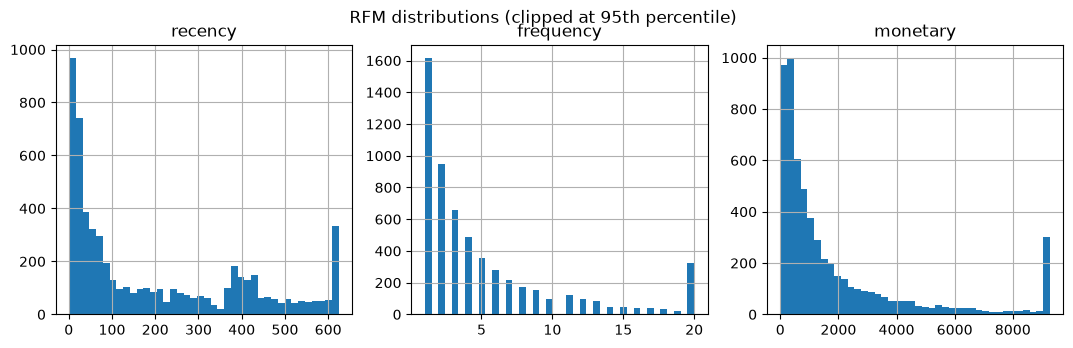

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["recency", "frequency", "monetary"]):
    rfm_pd[col].clip(upper=rfm_pd[col].quantile(0.95)).hist(bins=40, ax=ax)
    ax.set_title(col)
plt.suptitle("RFM distributions (clipped at 95th percentile)"); plt.show()

All three features are **heavily right-skewed**, so for clustering we apply `log1p` and standardise them first.

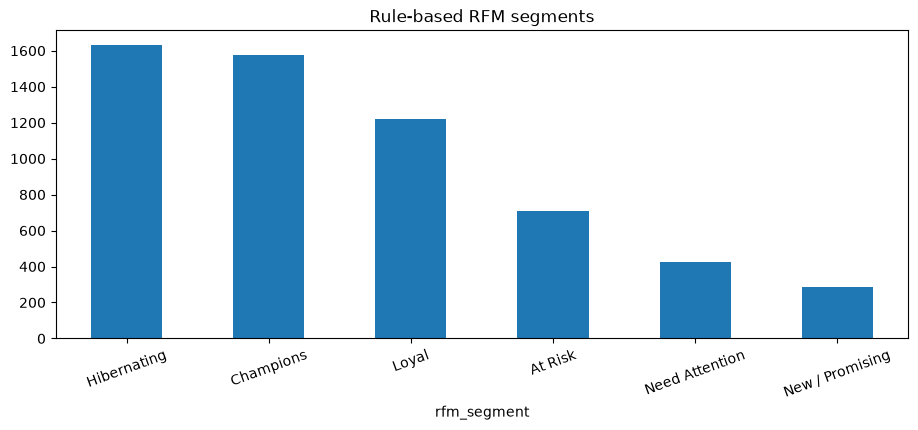

In [13]:
rfm_pd["rfm_segment"].value_counts().plot.bar(title="Rule-based RFM segments", rot=20); plt.show()

## 6. Spark MLlib — K-Means customer segmentation
Pipeline: `VectorAssembler` → `StandardScaler` → `KMeans`. We try k = 2…8 and use the **silhouette score** to choose k.

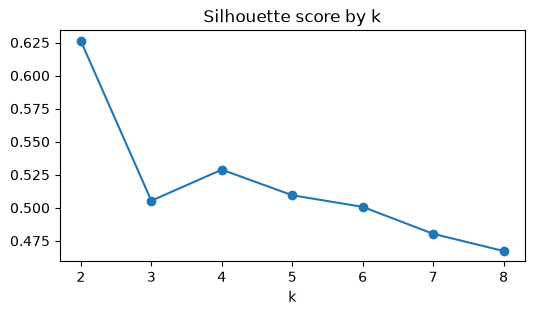

{2: 0.626, 3: 0.505, 4: 0.529, 5: 0.51, 6: 0.501, 7: 0.48, 8: 0.467}

In [14]:
from pyspark.ml import Pipeline
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.feature import VectorAssembler, StandardScaler

feats = rfm.select("customer_id", F.log1p("recency").alias("r"), F.log1p("frequency").alias("f"),
                   F.log1p(F.greatest("monetary", F.lit(0.0))).alias("m"))
assembler = VectorAssembler(inputCols=["r", "f", "m"], outputCol="raw")
scaler = StandardScaler(inputCol="raw", outputCol="features", withMean=True, withStd=True)
evaluator = ClusteringEvaluator(featuresCol="features")

scores, models = {}, {}
for k in range(2, 9):
    models[k] = Pipeline(stages=[assembler, scaler, KMeans(k=k, seed=42)]).fit(feats)
    scores[k] = evaluator.evaluate(models[k].transform(feats))
pd.Series(scores).plot(marker="o", title="Silhouette score by k", figsize=(6, 3)); plt.xlabel("k"); plt.show()
{k: round(v, 3) for k, v in scores.items()}

k = 2 scores highest but only splits customers into 'active' vs 'inactive'. We choose **k = 4**, the best score among k ≥ 3, because it gives more useful business segments (this is also what `04_ml.py` does by searching k = 3…6).

In [15]:
clusters = models[4].transform(feats).select("customer_id", F.col("prediction").alias("cluster"))
profile = (rfm.join(clusters, "customer_id").groupBy("cluster")
           .agg(F.count("*").alias("customers"), F.round(F.avg("recency"), 1).alias("avg_recency_days"),
                F.round(F.avg("frequency"), 1).alias("avg_orders"), F.round(F.avg("monetary"), 0).alias("avg_spend"))
           .orderBy(F.desc("avg_spend")).toPandas())
profile["cluster_name"] = ["High-Value Loyal", "Mid-Value Slipping", "Recent Low-Spend", "Lapsed / Lost"]
profile

,cluster,customers,avg_recency_days,avg_orders,avg_spend,cluster_name
0,3,1165,29.1,19.4,10726.0,High-Value Loyal
1,2,1430,237.5,5.0,1945.0,Mid-Value Slipping
2,0,1283,28.0,3.3,919.0,Recent Low-Spend
3,1,1974,387.6,1.4,310.0,Lapsed / Lost


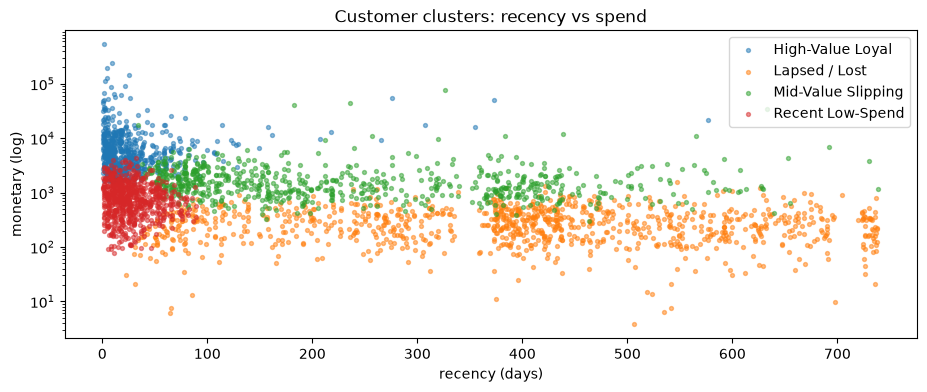

In [16]:
seg = rfm.join(clusters, "customer_id").toPandas().merge(profile[["cluster", "cluster_name"]], on="cluster")
for name, g in seg.sample(3000, random_state=1).groupby("cluster_name"):
    plt.scatter(g.recency, g.monetary.clip(lower=1), s=8, alpha=0.5, label=name)
plt.yscale("log"); plt.xlabel("recency (days)"); plt.ylabel("monetary (log)"); plt.legend()
plt.title("Customer clusters: recency vs spend"); plt.show()

## 7. Spark MLlib — ALS product recommendations
We treat *how many separate orders a customer bought a product in* as **implicit feedback** and train ALS (`implicitPrefs=True`). The model is validated on a random 20% hold-out using ranking metrics (`04_ml.py`).

In [17]:
with open(os.path.join(GOLD_DIR, "metrics.json")) as f:
    metrics = json.load(f)
pd.Series(metrics["als"], name="value").to_frame()

,value
rmse_implicit,1.9592
precision_at_10,0.0755
map_at_10,0.0455
hit_rate_at_10,0.4989
users,5852.0000
items,4620.0000
interactions,480973.0000


A **hit-rate@10 of ~0.50** means that for half of the customers, at least one product they actually bought in the hold-out set appeared in their top-10 recommendations — out of 4,620 possible products.

In [18]:
recs = spark.read.parquet(os.path.join(GOLD_DIR, "predictions", "recommendations"))
customer = 12346
print("Purchase history:")
sales.filter(F.col("customer_id") == customer).groupBy("description") \
     .agg(F.sum("quantity").alias("qty")).orderBy(F.desc("qty")).show(5, truncate=False)
print("Top-5 recommendations (not purchased before):")
recs.filter(F.col("customer_id") == customer).orderBy("rec_rank").show(truncate=False)

Purchase history:
+------------------------------+-----+
|description                   |qty  |
+------------------------------+-----+
|MEDIUM CERAMIC TOP STORAGE JAR|74215|
|EDWARDIAN PARASOL PINK        |1    |
|DOORMAT BLACK FLOCK           |1    |
|EDWARDIAN PARASOL RED         |1    |
|EDWARDIAN PARASOL NATURAL     |1    |
+------------------------------+-----+
only showing top 5 rows
Top-5 recommendations (not purchased before):


+-----------+--------+----------+-----------------------------+------+
|customer_id|rec_rank|stock_code|description                  |score |
+-----------+--------+----------+-----------------------------+------+
|12346      |1       |48184     |DOORMAT ENGLISH ROSE         |0.8721|
|12346      |2       |48129     |DOORMAT TOPIARY              |0.856 |
|12346      |3       |48194     |DOORMAT HEARTS               |0.8455|
|12346      |4       |48116     |DOOR MAT MULTICOLOUR STRIPE  |0.7931|
|12346      |5       |23284     |DOORMAT KEEP CALM AND COME IN|0.7231|
+-----------+--------+----------+-----------------------------+------+



## 8. Conclusions
- **£17.07M** revenue from **5,852** customers and **36,594** orders; strong Q4 seasonality.
- K-Means (k = 4, silhouette ≈ 0.53) finds four clear groups: *High-Value Loyal*, *Mid-Value Slipping*, *Recent Low-Spend* and *Lapsed / Lost*.
- ALS recommendations are sensible (similar product families) with hit-rate@10 ≈ 0.50.

**Business actions:** reward High-Value Loyal customers, run win-back campaigns for Mid-Value Slipping, use ALS cross-sell to grow baskets of Recent Low-Spend customers, and plan campaigns before the November peak.

The same results are shown interactively in the Streamlit dashboard (`streamlit run dashboard/app.py`).

In [19]:
spark.stop()